## <span style="color: #EE82EE;">**Разработка системы анализа пользовательских предпочтений в кино методами машинного обучения**</span>

In [9]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

MOVIELENS_PATH = Path("data/raw/ml-latest-small")

ratings = pd.read_csv(MOVIELENS_PATH / "ratings.csv")
movies = pd.read_csv(MOVIELENS_PATH / "movies.csv")
tags = pd.read_csv(MOVIELENS_PATH / "tags.csv")

#### <span style="color: #EE82EE;">**Разделение набора на исходную часть и порции**</span>

In [7]:
RAW_DIR = Path("data/raw")
INCOMING_DIR = Path("data/incoming")

ratings = ratings.sort_values("timestamp").reset_index(drop=True)

n = len(ratings)
train_end = int(n * 0.60)
batch_size = int(n * 0.40 / 4)

train_initial = ratings.iloc[:train_end].copy()
train_initial.to_csv(RAW_DIR / "train_initial.csv", index=False)
movies.to_csv(RAW_DIR / "movies.csv", index=False)

batches = {}
for i in range(4):
    start = train_end + i * batch_size
    end = train_end + (i + 1) * batch_size if i < 3 else n
    name = f"batch_0{i+1}"
    batches[name] = ratings.iloc[start:end].copy()
    batches[name].to_csv(INCOMING_DIR / f"{name}.csv", index=False)

#### <span style="color: #EE82EE;">**Анализ целевой переменной**</span>

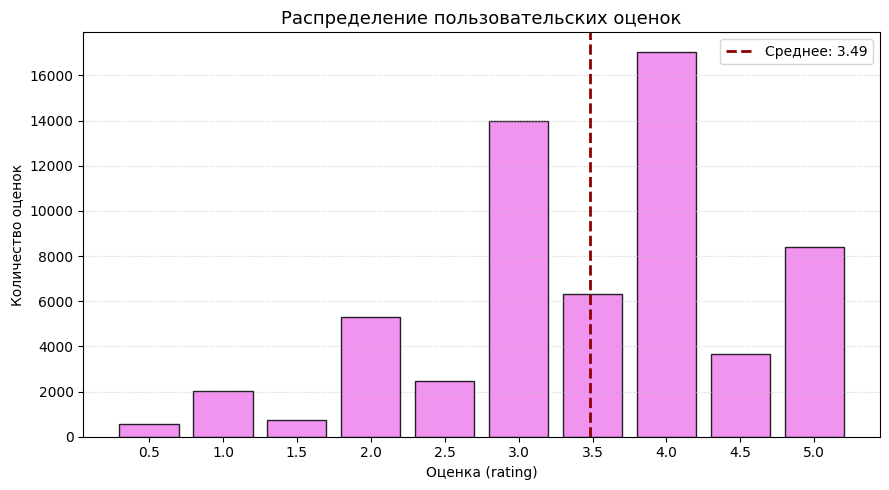

In [10]:
mean_rating = train_initial['rating'].mean()
counts = train_initial['rating'].value_counts().sort_index()

plt.figure(figsize=(9, 5))
plt.bar(counts.index.astype(str), counts.values, color='#EE82EE', edgecolor='black', alpha=0.85)

x_pos = (mean_rating - 0.5) / 0.5
plt.axvline(x_pos, color='darkred', linestyle='--', linewidth=2, label=f'Среднее: {mean_rating:.2f}')

plt.title('Распределение пользовательских оценок', fontsize=13)
plt.xlabel('Оценка (rating)')
plt.ylabel('Количество оценок')
plt.grid(axis='y', linestyle=':', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

In [19]:
balance = (train_initial['rating'] >= 4.0).value_counts(normalize=True) * 100
print(f"Релевантные (>=4.0): {balance[True]:.1f}%\nНерелевантные (<4.0): {balance[False]:.1f}%")

Релевантные (>=4.0): 48.1%
Нерелевантные (<4.0): 51.9%


#### <span style="color: #EE82EE;">**Оценка качества данных**</span>

In [20]:
print("1. Пропуски:\n", train_initial.isna().sum())
print("2. Точные дубли:", train_initial.duplicated().sum())
print("   Дубли пар userId-movieId:", train_initial.duplicated(subset=['userId', 'movieId']).sum())
print("3. Ошибки ID (<= 0):", ((train_initial['userId'] <= 0) | (train_initial['movieId'] <= 0)).sum())
print("   Ошибки рейтинга:", (~train_initial['rating'].isin([x * 0.5 for x in range(1, 11)])).sum())
print("   Диапазон дат:", pd.to_datetime(train_initial['timestamp'], unit='s').agg(['min', 'max']).to_dict())

1. Пропуски:
 userId       0
movieId      0
rating       0
timestamp    0
dtype: int64
2. Точные дубли: 0
   Дубли пар userId-movieId: 0
3. Ошибки ID (<= 0): 0
   Ошибки рейтинга: 0
   Диапазон дат: {'min': Timestamp('1996-03-29 18:36:55'), 'max': Timestamp('2009-11-17 01:21:40')}


#### <span style="color: #EE82EE;">**Распределение пользовательской активности**</span>

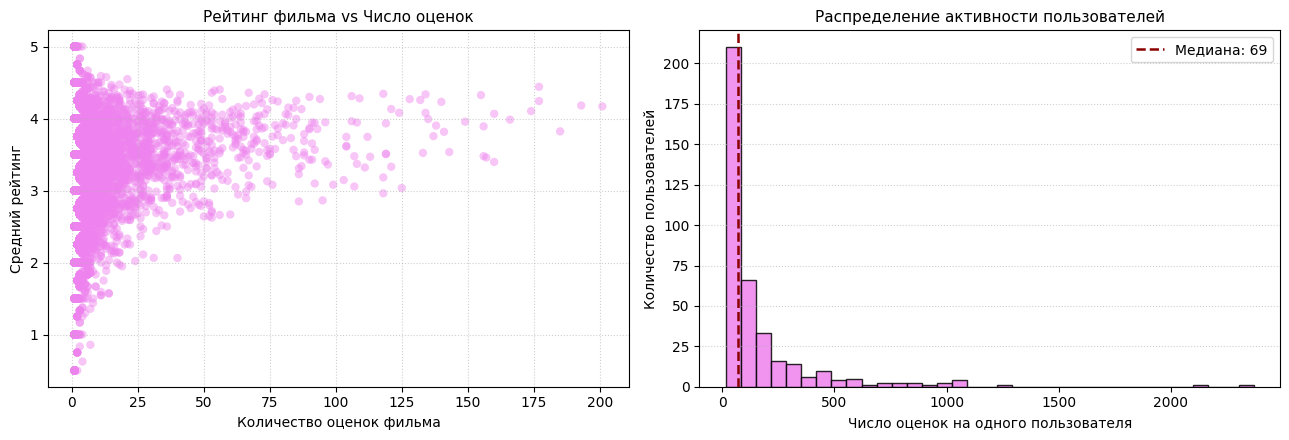

In [24]:
m_stats = train_initial.groupby('movieId')['rating'].agg(['count', 'mean'])
u_counts = train_initial.groupby('userId')['rating'].count()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

ax1.scatter(m_stats['count'], m_stats['mean'], color='#EE82EE', alpha=0.45, edgecolors='none')
ax1.set_title('Рейтинг фильма vs Число оценок', fontsize=11)
ax1.set_xlabel('Количество оценок фильма')
ax1.set_ylabel('Средний рейтинг')
ax1.grid(True, linestyle=':', alpha=0.6)

ax2.hist(u_counts, bins=35, color='#EE82EE', edgecolor='black', alpha=0.85)
ax2.axvline(u_counts.median(), color='darkred', linestyle='--', linewidth=1.8, 
            label=f'Медиана: {u_counts.median():.0f}')
ax2.set_title('Распределение активности пользователей', fontsize=11)
ax2.set_xlabel('Число оценок на одного пользователя')
ax2.set_ylabel('Количество пользователей')
ax2.grid(axis='y', linestyle=':', alpha=0.6)
ax2.legend()

plt.tight_layout()
plt.show()

In [5]:
# Проверяем, что timestamp — это Unix-epoch в секундах
print("Типы данных:")
print(ratings.dtypes)
print("\nДиапазон timestamp:")
print(f"  min: {ratings['timestamp'].min()}  -> {pd.to_datetime(ratings['timestamp'].min(), unit='s')}")
print(f"  max: {ratings['timestamp'].max()}  -> {pd.to_datetime(ratings['timestamp'].max(), unit='s')}")

# Сортируем строго по времени (time-based split)
ratings = ratings.sort_values("timestamp").reset_index(drop=True)
print(f"\nДанные отсортированы по timestamp. Всего записей: {len(ratings)}")

Типы данных:
userId         int64
movieId        int64
rating       float64
timestamp      int64
dtype: object

Диапазон timestamp:
  min: 828124615  -> 1996-03-29 18:36:55
  max: 1537799250  -> 2018-09-24 14:27:30

Данные отсортированы по timestamp. Всего записей: 100836


In [6]:
import pandas as pd
from pathlib import Path

# Убедимся, что директории существуют
RAW_DIR = Path("data/raw")
INCOMING_DIR = Path("data/incoming")
RAW_DIR.mkdir(parents=True, exist_ok=True)
INCOMING_DIR.mkdir(parents=True, exist_ok=True)

# 1. Рассчитываем индексы для разделения
n = len(ratings)
train_share = 0.60
n_batches = 4

train_end_idx = int(n * train_share)
batch_size = int(n * (1 - train_share) / n_batches)

print(f"Всего записей: {n}")
print(f"Индекс конца обучающей выборки (60%): {train_end_idx}")
print(f"Размер одного батча (~10%): {batch_size}\n")

# 2. Разделяем данные
train_initial = ratings.iloc[:train_end_idx].copy()

batches = {}
for i in range(n_batches):
    start_idx = train_end_idx + i * batch_size
    # Последний батч забирает все оставшиеся записи до конца, чтобы ничего не потерялось из-за округления
    end_idx = train_end_idx + (i + 1) * batch_size if i < n_batches - 1 else n
    
    batch_name = f"batch_0{i+1}"
    batches[batch_name] = ratings.iloc[start_idx:end_idx].copy()

# 3. Выводим статистику по разбиению (можно использовать для отчета)
print("=== Статистика разбиения данных ===")
print(f"train_initial : {len(train_initial):>6} записей | "
      f"Период: {pd.to_datetime(train_initial['timestamp'].min(), unit='s').date()} — "
      f"{pd.to_datetime(train_initial['timestamp'].max(), unit='s').date()}")

for name, df in batches.items():
    print(f"{name}    : {len(df):>6} записей | "
          f"Период: {pd.to_datetime(df['timestamp'].min(), unit='s').date()} — "
          f"{pd.to_datetime(df['timestamp'].max(), unit='s').date()}")

# 4. Сохраняем файлы
# Сохраняем исходную обучающую часть и справочник фильмов в data/raw
train_initial.to_csv(RAW_DIR / "train_initial.csv", index=False)
movies.to_csv(RAW_DIR / "movies.csv", index=False)

# Сохраняем батчи в data/incoming
for name, df in batches.items():
    file_path = INCOMING_DIR / f"{name}.csv"
    df.to_csv(file_path, index=False)

Всего записей: 100836
Индекс конца обучающей выборки (60%): 60501
Размер одного батча (~10%): 10083

=== Статистика разбиения данных ===
train_initial :  60501 записей | Период: 1996-03-29 — 2009-11-17
batch_01    :  10083 записей | Период: 2009-11-17 — 2013-08-18
batch_02    :  10083 записей | Период: 2013-08-18 — 2016-03-22
batch_03    :  10083 записей | Период: 2016-03-22 — 2017-06-21
batch_04    :  10086 записей | Период: 2017-06-21 — 2018-09-24


In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Настройка стиля графиков для отчета
sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams['figure.figsize'] = (10, 6)

DATA_DIR = Path("data")
train_df = pd.read_csv(DATA_DIR / "raw" / "train_initial.csv")
movies_df = pd.read_csv(DATA_DIR / "raw" / "movies.csv")

# Объединяем для обогащенного анализа (но помним, что признаки должны быть доступны в момент предсказания)
df = pd.merge(train_df, movies_df, on="movieId", how="left")

# Преобразуем timestamp в даты для удобства анализа
df['date'] = pd.to_datetime(df['timestamp'], unit='s')
df['year'] = df['date'].dt.year

# Подсчет количества жанров для гипотез
df['num_genres'] = df['genres'].apply(lambda x: len(str(x).split('|')) if pd.notna(x) else 0)

print("✅ Данные загружены и подготовлены к EDA.")

✅ Данные загружены и подготовлены к EDA.


In [8]:
print("=== 3. Оценка качества данных ===")
print(f"Пропуски (NaN):\n{train_df.isna().sum()}\n")

# Дубликаты пар (пользователь, фильм)
duplicates = train_df.duplicated(subset=['userId', 'movieId']).sum()
print(f"Дубликаты пар (userId, movieId): {duplicates}")

# Невозможные значения рейтинга
invalid_ratings = train_df[(train_df['rating'] < 0.5) | (train_df['rating'] > 5.0) | ((train_df['rating'] * 2) % 1 != 0)]
print(f"Записи с некорректным рейтингом (вне 0.5-5.0 или не кратно 0.5): {len(invalid_ratings)}")

=== 3. Оценка качества данных ===
Пропуски (NaN):
userId       0
movieId      0
rating       0
timestamp    0
dtype: int64

Дубликаты пар (userId, movieId): 0
Записи с некорректным рейтингом (вне 0.5-5.0 или не кратно 0.5): 0


In [17]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Настройка вывода таблиц, чтобы видеть все колонки
pd.set_option('display.max_columns', None)
# Настройка стиля графиков
sns.set_theme(style="whitegrid")

# 1. Загрузка данных
df = train_df

# 2. Базовая информация о структуре
print("Размер датасета")
print(f"Строк: {df.shape[0]}, Колонок: {df.shape[1]}\n")

print("Типы данных и пропуски")
print(df.info())

print("\nПервые 5 строк")
print(df.head())

print("Явные дубликаты")
duplicated_count = df.duplicated().sum()
print(f"Найдено полных дубликатов: {duplicated_count}")
if duplicated_count > 0:
    print("Рекомендация: удалить через df.drop_duplicates()")

print("\nПропущенные значения (в %)")
missing_pct = (df.isnull().sum() / len(df) * 100).round(2)
print(missing_pct[missing_pct > 0].sort_values(ascending=False))

print("\nОписательная статистика (Числовые признаки)")
print(df.describe().T)

print("\nОписательная статистика (Категориальные признаки)")
# Выбираем только текстовые/категориальные колонки
cat_cols = df.select_dtypes(include=['object', 'category']).columns
if not cat_cols.empty:
    print(df[cat_cols].describe().T)
else:
    print("Категориальные признаки отсутствуют.")


Размер датасета
Строк: 60501, Колонок: 4

Типы данных и пропуски
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 60501 entries, 0 to 60500
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   userId     60501 non-null  int64  
 1   movieId    60501 non-null  int64  
 2   rating     60501 non-null  float64
 3   timestamp  60501 non-null  int64  
dtypes: float64(1), int64(3)
memory usage: 1.8 MB
None

Первые 5 строк
   userId  movieId  rating  timestamp
0     429      595     5.0  828124615
1     429      588     5.0  828124615
2     429      590     5.0  828124615
3     429      592     5.0  828124615
4     429      432     3.0  828124615
Явные дубликаты
Найдено полных дубликатов: 0

Пропущенные значения (в %)
Series([], dtype: float64)

Описательная статистика (Числовые признаки)
             count          mean           std          min          25%  \
userId     60501.0  3.162540e+02  1.793390e+02          1.0        

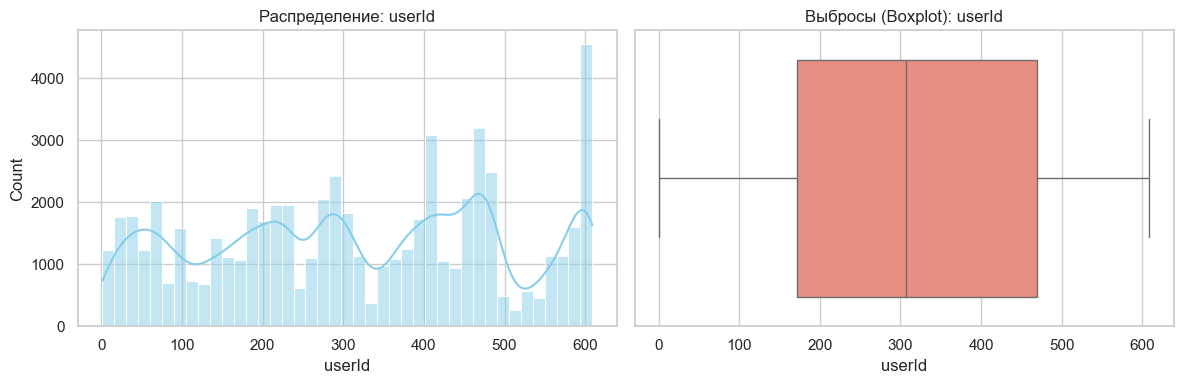

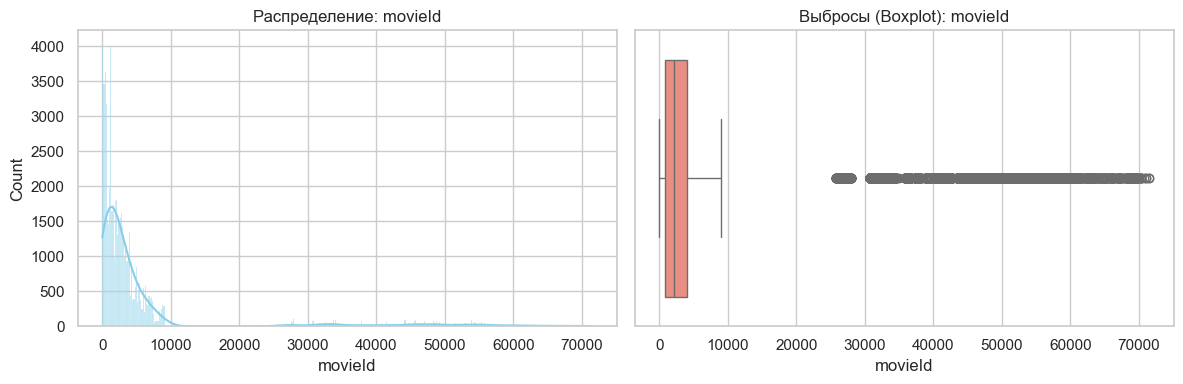

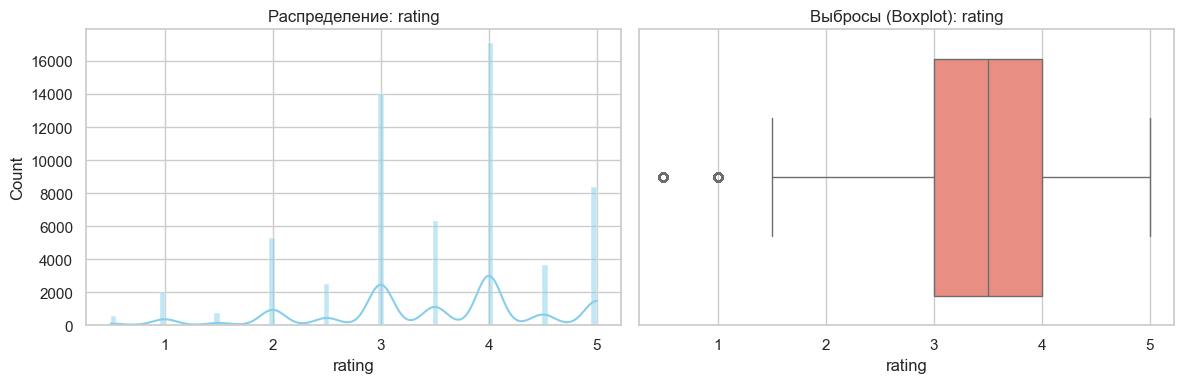

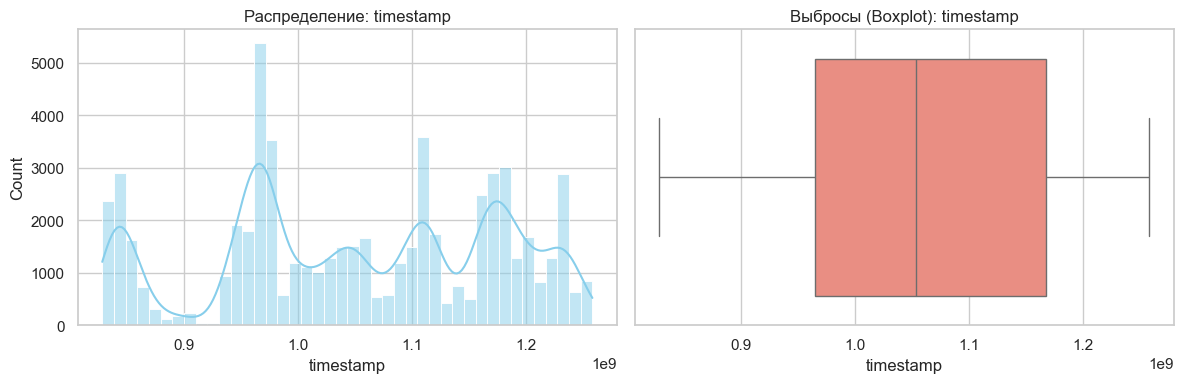

In [18]:
# Разделяем признаки на числовые и текстовые для графиков
num_cols = df.select_dtypes(include=[np.number]).columns
cat_cols = df.select_dtypes(include=['object', 'category']).columns

# Строим гистограммы и ящики с усами для числовых признаков
for col in num_cols:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    
    # Гистограмма распределения
    sns.histplot(df[col], kde=True, ax=axes[0], color='skyblue')
    axes[0].set_title(f'Распределение: {col}')
    
    # Boxplot для поиска выбросов
    sns.boxplot(x=df[col], ax=axes[1], color='salmon')
    axes[1].set_title(f'Выбросы (Boxplot): {col}')
    
    plt.tight_layout()
    plt.show()

# Строим столбчатые диаграммы для категориальных признаков
for col in cat_cols:
    if df[col].nunique() <= 15: # Ограничиваем, чтобы график не перегружался
        plt.figure(figsize=(8, 4))
        sns.countplot(data=df, y=col, order=df[col].value_counts().index, palette='viridis')
        plt.title(f'Частота категорий: {col}')
        plt.show()
    else:
        print(f"В колонке '{col}' слишком много уникальных значений ({df[col].nunique()}) для графика.")
